<a href="https://colab.research.google.com/github/Castycarlos/Optativa-IA/blob/main/pr%C3%A1ctica_2_3_teachable_machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

En esta práctica se debe exportar el modelo que se genera en Teachable Machine.

A la hora de exportar el modelo, se puede exportar para Tensorflow.

También viene un fragmento de código para usar el modelo:

```
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

```

**Tarea**: subir 3 imágenes propias (una clara, una ambigua, una que no pertenezca a ninguna categoría) y anotar qué predice y con qué confianza.

**¡Ojo! Hay que cargar una  versión anterior de Keras**

In [1]:
# forzar TensorFlow a usar el comportamiento clásico de Keras 2
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import tensorflow as tf
import tf_keras as keras

print("Versión de TensorFlow:", tf.__version__)
print("Versión de TF-Keras (Legacy):", keras.__version__)

try:
    # Cargamos el modelo utilizando el módulo de compatibilidad oficial tf_keras
    model = keras.models.load_model('keras_model.h5', compile=False)
    print("\n¡MODELO CARGADO CON ÉXITO!")
    model.summary()
except Exception as e:
    print(f"\nError al cargar: {e}")

Versión de TensorFlow: 2.21.0
Versión de TF-Keras (Legacy): 2.21.0

¡MODELO CARGADO CON ÉXITO!
Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 1280)              410208    
                                                                 
 sequential_3 (Sequential)   (None, 3)                 128400    
                                                                 
Total params: 538608 (2.05 MB)
Trainable params: 524528 (2.00 MB)
Non-trainable params: 14080 (55.00 KB)
_________________________________________________________________


In [4]:
import tensorflow as tf
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np

class_names = open("labels.txt", "r").readlines()
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
image = Image.open("vinorico.jpg").convert("RGB")
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)
image_array = np.asarray(image)
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1
data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

1/1 [==============================] - 1s 996ms/step
Class: Botella de Vino
Confidence Score: 0.6341457


In [8]:
import numpy as np
from PIL import Image, ImageOps

class_names = open("labels.txt", "r").readlines()

def clasificacion(ruta):
    image = Image.open(ruta).convert("RGB")
    image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
    data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
    data[0] = (np.asarray(image).astype(np.float32) / 127.5) - 1

    prediction = model.predict(data)[0]
    index = np.argmax(prediction)
    print("Imagen:", ruta)
    print("Clase:", class_names[index][2:].strip())
    print("Confianza:", round(float(prediction[index]) * 100, 2), "%")
    for nombre, p in zip(class_names, prediction):
        print("  -", nombre[2:].strip(), ":", round(float(p) * 100, 2), "%")
    display(image)

1/1 [==============================] - 0s 46ms/step
Imagen: vinorico.jpg
Clase: Botella de Vino
Confianza: 63.41 %
  - Botella de Vino : 63.41 %
  - Bote Spray : 36.36 %
  - Pizza : 0.23 %


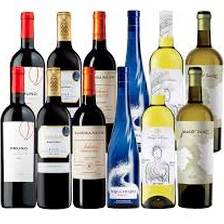

In [10]:
# implementa la clasificación con la imagen que pertenece claramente a una categoría
clasificacion("vinorico.jpg")

1/1 [==============================] - 0s 39ms/step
Imagen: agua.jpg
Clase: Bote Spray
Confianza: 99.36 %
  - Botella de Vino : 0.63 %
  - Bote Spray : 99.36 %
  - Pizza : 0.01 %


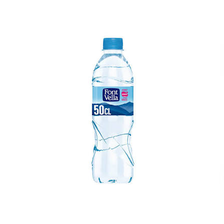

In [11]:
# implementa la clasificación con una imagen ambigua, que puede ser de cualquier categoría
clasificacion("agua.jpg")

1/1 [==============================] - 0s 37ms/step
Imagen: coche.jpg
Clase: Botella de Vino
Confianza: 95.92 %
  - Botella de Vino : 95.92 %
  - Bote Spray : 0.64 %
  - Pizza : 3.44 %


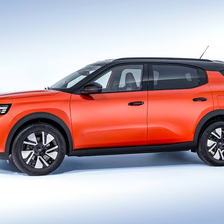

In [12]:
# implementa la clasificación con una imagen sin ninguna categoría del modeloç
clasificacion("coche.jpg")

**¿Cómo se usa el modelo exportado? ¿Cómo se comporta?**

---



**¿Cómo se usa el modelo exportado?**
Descargo el modelo de Teachable Machine en formato Keras (`keras_model.h5`) y el archivo `labels.txt` con los nombres de las clases. Los subo a Colab, cargo el modelo y le paso una imagen (redimensionada a 224x224). El modelo me devuelve un porcentaje para cada clase y la predicción es la que tiene el porcentaje más alto.

**¿Cómo se comporta?**
- Con la imagen clara (botellas de vino) acertó, pero solo con un 63,41 % de seguridad, porque también dio un 36,36 % a Bote Spray.
- Con la imagen ambigua (botella de agua) dijo Bote Spray con un 99,36 %. Esperaba que dudara más entre las dos clases.
- Con la imagen sin categoría (un coche) dijo Botella de Vino con un 95,92 %, aunque no se parece a nada del modelo.